DATA SOURCE → LOAD (Documents) → CHUNK → EMBED → STORE IN VECTOR DB (knowledge base)
                                                          ↓
                                        USER QUERY → RETRIEVE (top-k) → LLM + PROMPT → ANSWER

**feeds the pipeline a PDF → output is a generated Question + Answer CSV.**

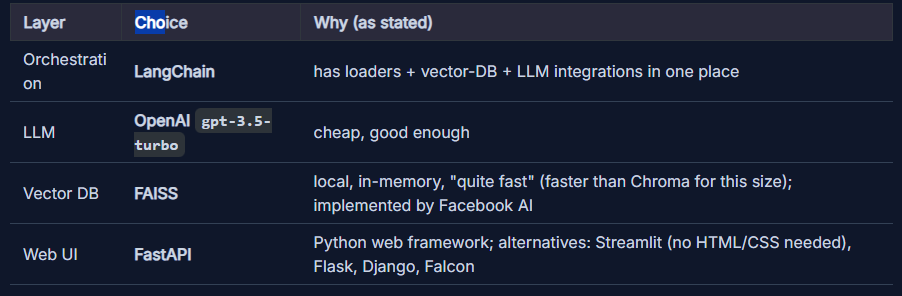

**Architecture**
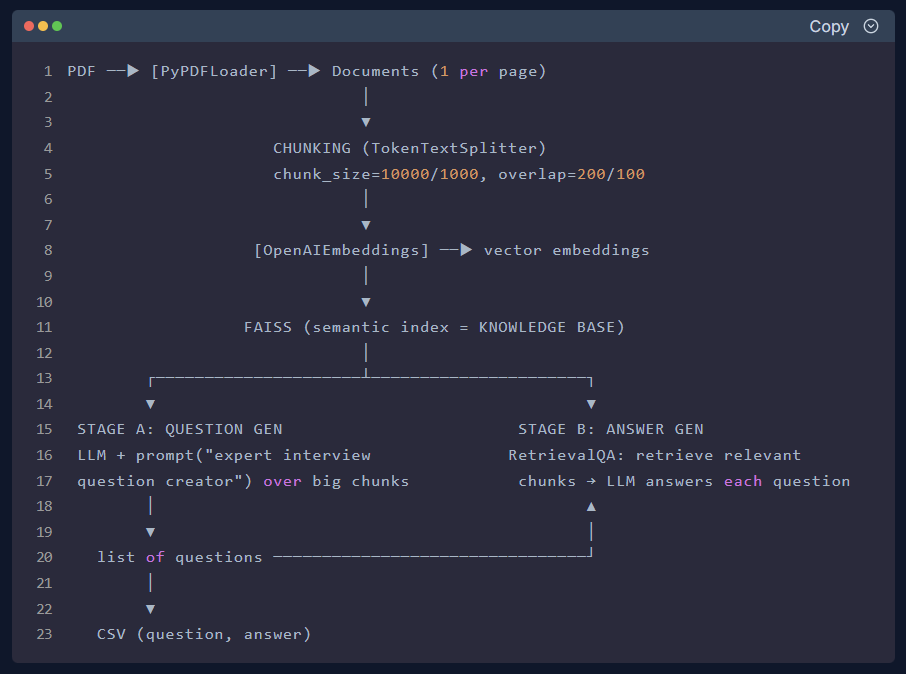

In [2]:
!pip install -q langchain-core langchain-community langchain-groq langchain-huggingface langchain-text-splitters pypdf tiktoken faiss-cpu sentence-transformers fpdf2 gradio

In [3]:
import os
from google.colab import userdata

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
print("Groq key loaded:", bool(os.environ["GROQ_API_KEY"]))

Groq key loaded: True


In [4]:
from groq import Groq
from langchain_groq import ChatGroq

client = Groq(api_key=os.environ["GROQ_API_KEY"])
available = sorted(m.id for m in client.models.list().data)
print("Available:", available)

prefer = ["llama-3.3-70b-versatile", "openai/gpt-oss-120b", "openai/gpt-oss-20b",
          "llama-3.1-8b-instant", "qwen/qwen3-32b"]
skip = ("whisper", "tts", "guard", "orpheus", "compound")
MODEL = next((m for m in prefer if m in available),
             next(m for m in available if not any(x in m for x in skip)))
print("Using:", MODEL)

def get_llm(temperature):
    # max_retries -> automatically waits & retries if the free rate limit is hit
    return ChatGroq(model=MODEL, temperature=temperature, max_retries=6)

Available: ['allam-2-7b', 'canopylabs/orpheus-arabic-saudi', 'canopylabs/orpheus-v1-english', 'meta-llama/llama-prompt-guard-2-22m', 'meta-llama/llama-prompt-guard-2-86m', 'openai/gpt-oss-120b', 'openai/gpt-oss-20b', 'openai/gpt-oss-safeguard-20b', 'qwen/qwen3.8-27b', 'whisper-large-v3', 'whisper-large-v3-turbo']
Using: openai/gpt-oss-120b


In [6]:
# generate a small sample PDF (skip if you used Option A)
from fpdf import FPDF

sample_pages = [
    "Correlation measures how strongly two variables move together. The correlation coefficient, "
    "usually written r, ranges from -1 to +1. A value near +1 means a strong positive relationship, "
    "near -1 means a strong negative relationship, and near 0 means little or no linear relationship.",
    "Correlation does not imply causation. Two variables can move together because of a hidden third "
    "factor, called a confounder. Pearson correlation measures linear relationships, while Spearman "
    "correlation uses ranks and works for monotonic relationships and ordinal data.",
    "Outliers can strongly distort Pearson correlation. A scatter plot is the best first step: it shows "
    "the shape of the relationship, clusters and outliers before you trust a single number.",
]
pdf = FPDF()
for t in sample_pages:
    pdf.add_page(); pdf.set_font("Helvetica", size=12); pdf.multi_cell(0, 8, t)
pdf.output("sample.pdf")
file_path = "sample.pdf"
print("Using:", file_path)

Using: sample.pdf


In [7]:
from langchain_community.document_loaders import PyPDFLoader

data = PyPDFLoader(file_path).load()
print("Pages:", len(data))
print(data[0].page_content[:400])

Pages: 3
Correlation measures how strongly two variables move together. The correlation coefficient, usually
written r, ranges from -1 to +1. A value near +1 means a strong positive relationship, near -1 means
a strong negative relationship, and near 0 means little or no linear relationship.


/tmp/ipykernel_1021/3904603506.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [9]:
#Merge pages into one string
question_gen = ""
for page in data:
    question_gen += page.page_content
print("Characters:", len(question_gen))

Characters: 737


In [10]:
## — Coarse chunking (for QUESTION generation)
#`TokenTextSplitter` measures `chunk_size` in **tokens**; `chunk_overlap` is the margin shared with the next chunk so ideas aren't cut in half.
#It does **not** call an LLM — it only counts tokens (the video's claim otherwise is a common misunderstanding).
from langchain_text_splitters import TokenTextSplitter
from langchain_core.documents import Document

splitter_ques_gen = TokenTextSplitter(encoding_name="cl100k_base", chunk_size=3000, chunk_overlap=200)
chunk_ques_gen = splitter_ques_gen.split_text(question_gen)          # list[str]
document_ques_gen = [Document(page_content=t) for t in chunk_ques_gen]   # strings -> Documents

print("Coarse chunks:", len(document_ques_gen))

Coarse chunks: 1


## Fine chunking (for ANSWER retrieval)
Rule of thumb: **big chunks to generate, small chunks to retrieve.**

In [11]:
splitter_ans_gen = TokenTextSplitter(encoding_name="cl100k_base", chunk_size=500, chunk_overlap=50)
document_answer_gen = splitter_ans_gen.split_documents(document_ques_gen)
print("Fine chunks:", len(document_answer_gen))

Fine chunks: 1






## The prompts (first pass + refine pass)
Change `SUBJECT` to match your PDF (e.g. `"coding materials"`, `"statistics"`). A mismatched subject visibly hurts quality.

In [13]:
from langchain_core.prompts import PromptTemplate

SUBJECT = "the study material provided"
NUM_QUESTIONS = 10

prompt_template = """
You are an expert at creating exam and interview questions based on {subject}.
Your goal is to prepare a student or candidate for their exam or interview.
You do this by asking questions about the text below:

------------
{text}
------------

Create {num} questions that will prepare them for their test.
Write exactly one question per line and end each with a question mark.
Do not add any introduction or closing text.

QUESTIONS:
"""

refine_template = """
You are an expert at creating practice questions based on {subject}.
Your goal is to help a student or candidate prepare for a test.
We have received these practice questions so far:
{existing_answer}

We may refine the existing questions or add new ones (only if necessary)
using the extra context below.
------------
{text}
------------

Given the new context, refine the original questions in English.
If the context is not helpful, return the original questions unchanged.
Keep at most {num} questions, one per line, each ending with a question mark.
Do not add any introduction or closing text.

QUESTIONS:
"""

partial = {"subject": SUBJECT, "num": str(NUM_QUESTIONS)}
PROMPT_QUESTIONS = PromptTemplate(template=prompt_template, input_variables=["text"], partial_variables=partial)
REFINE_PROMPT_QUESTIONS = PromptTemplate(template=refine_template, input_variables=["existing_answer", "text"], partial_variables=partial)
print("Prompts ready")

Prompts ready


##  Generate the questions (the "refine" idea)
Chunk 1 → first questions. Each later chunk → *refine/extend* the running list. Result: one coherent set, not N disconnected lists.
(This replaces `load_summarize_chain(chain_type="refine")`, which is removed in newer LangChain.)

In [14]:
from langchain_core.output_parsers import StrOutputParser

llm_ques_gen = get_llm(0.3)          # 0.3 = a little variety, still on-topic
first_chain  = PROMPT_QUESTIONS | llm_ques_gen | StrOutputParser()
refine_chain = REFINE_PROMPT_QUESTIONS | llm_ques_gen | StrOutputParser()

ques = first_chain.invoke({"text": document_ques_gen[0].page_content})
for doc in document_ques_gen[1:]:
    ques = refine_chain.invoke({"existing_answer": ques, "text": doc.page_content})

print(ques)

What is the range of values that the correlation coefficient (r) can take?  
What does a correlation coefficient near +1 indicate about the relationship between two variables?  
What does a correlation coefficient near -1 indicate about the relationship between two variables?  
What does a correlation coefficient near 0 suggest about the linear relationship between two variables?  
Why is it important to remember that correlation does not imply causation?  
What is a confounder, and how can it affect the interpretation of a correlation?  
How does Pearson correlation differ from Spearman correlation in terms of the types of relationships they measure?  
In what situations is Spearman correlation more appropriate than Pearson correlation?  
Why can outliers strongly distort Pearson correlation, and how can this be detected?  
What is the purpose of creating a scatter plot before relying on a single correlation number?


### Clean the output
LLMs sometimes add chatter ("Here are your questions:") or numbering. We strip numbers and keep only lines ending with `?`.

In [16]:
import re

def clean_questions(raw):
    out = []
    for line in raw.split("\n"):
        line = re.sub(r"^\s*(\d+[\.\)]|[-*•])\s*", "", line).strip()
        if line.endswith("?"):
            out.append(line)
    return out

ques_list = clean_questions(ques)
print(len(ques_list), "questions")
for q in ques_list:
    print("-", q)

10 questions
- What is the range of values that the correlation coefficient (r) can take?
- What does a correlation coefficient near +1 indicate about the relationship between two variables?
- What does a correlation coefficient near -1 indicate about the relationship between two variables?
- What does a correlation coefficient near 0 suggest about the linear relationship between two variables?
- Why is it important to remember that correlation does not imply causation?
- What is a confounder, and how can it affect the interpretation of a correlation?
- How does Pearson correlation differ from Spearman correlation in terms of the types of relationships they measure?
- In what situations is Spearman correlation more appropriate than Pearson correlation?
- Why can outliers strongly distort Pearson correlation, and how can this be detected?
- What is the purpose of creating a scatter plot before relying on a single correlation number?


##Knowledge base: free local embeddings + FAISS
FAISS is local & in-memory — nothing is uploaded anywhere (that's why there's no dashboard like Pinecone's).
First run downloads the small embedding model (~90 MB).

In [17]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
vector_store = FAISS.from_documents(document_answer_gen, embeddings)

# quick test: what chunk is closest in meaning to this query?
hits = vector_store.similarity_search("What does the correlation coefficient mean?", k=1)
print(hits[0].page_content[:300])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Correlation measures how strongly two variables move together. The correlation coefficient, usually
written r, ranges from -1 to +1. A value near +1 means a strong positive relationship, near -1 means
a strong negative relationship, and near 0 means little or no linear relationship.Correlation does 


##Answer generation with retrieval (replaces `RetrievalQA`)
For each question: retrieve the closest chunks → give them to the LLM → answer **only** from that context. `temperature=0.1` because answers must be factual.

In [18]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough

answer_template = """
Answer the question using ONLY the context below. Be clear and concise.
If the context does not contain the answer, say "Not covered in the document."

Context:
{context}

Question: {question}

Answer:
"""

retriever = vector_store.as_retriever(search_kwargs={"k": 4})
format_docs = lambda docs: "\n\n".join(d.page_content for d in docs)

llm_answer_gen = get_llm(0.1)
answer_generation_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}
    | ChatPromptTemplate.from_template(answer_template)
    | llm_answer_gen
    | StrOutputParser()
)

# try one question first
print(ques_list[0])
print(answer_generation_chain.invoke(ques_list[0]))

What is the range of values that the correlation coefficient (r) can take?
The correlation coefficient (r) can range from **‑1 to +1**.


##Run all questions → `QA.csv`

In [19]:
import csv, time

output_file = "QA.csv"
with open(output_file, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["Question", "Answer"])
    for question in ques_list:
        answer = answer_generation_chain.invoke(question)
        print("Q:", question, "\nA:", answer, "\n" + "-" * 50)
        writer.writerow([question, answer])
        time.sleep(1)          # gentle on the free rate limit

print("Saved", output_file)

Q: What is the range of values that the correlation coefficient (r) can take? 
A: The correlation coefficient r can range from **‑1 to +1**. 
--------------------------------------------------
Q: What does a correlation coefficient near +1 indicate about the relationship between two variables? 
A: A correlation coefficient near +1 indicates a strong positive relationship between the two variables. 
--------------------------------------------------
Q: What does a correlation coefficient near -1 indicate about the relationship between two variables? 
A: A correlation coefficient near -1 indicates a strong negative relationship between the two variables. 
--------------------------------------------------
Q: What does a correlation coefficient near 0 suggest about the linear relationship between two variables? 
A: A correlation coefficient near 0 indicates little or no linear relationship between the two variables. 
--------------------------------------------------
Q: Why is it importan

In [20]:
import pandas as pd
pd.set_option("display.max_colwidth", 200)
pd.read_csv("QA.csv")

,Question,Answer
0,What is the range of values that the correlation coefficient (r) can take?,The correlation coefficient r can range from **‑1 to +1**.
1,What does a correlation coefficient near +1 indicate about the relationship between two variables?,A correlation coefficient near +1 indicates a strong positive relationship between the two variables.
2,What does a correlation coefficient near -1 indicate about the relationship between two variables?,A correlation coefficient near -1 indicates a strong negative relationship between the two variables.
3,What does a correlation coefficient near 0 suggest about the linear relationship between two variables?,A correlation coefficient near 0 indicates little or no linear relationship between the two variables.
4,Why is it important to remember that correlation does not imply causation?,Because a strong correlation may arise from a hidden third factor (a confounder) rather than one variable causing the other; assuming causation from correlation can lead to incorrect conclusions.
5,"What is a confounder, and how can it affect the interpretation of a correlation?","A confounder is a hidden third factor that influences both variables, causing them to move together. Because the observed correlation may be driven by this confounding factor rather than a direct ..."
6,How does Pearson correlation differ from Spearman correlation in terms of the types of relationships they measure?,"Pearson correlation quantifies **linear** relationships between variables, whereas Spearman correlation, which is based on ranks, captures **monotonic** relationships (including those in ordinal d..."
7,In what situations is Spearman correlation more appropriate than Pearson correlation?,"Spearman correlation is preferable when the relationship between variables is monotonic rather than strictly linear, or when the data are ordinal (i.e., based on ranks)."
8,"Why can outliers strongly distort Pearson correlation, and how can this be detected?",Outliers can have a large influence on the Pearson correlation because the coefficient is calculated from the actual data values; extreme points can pull the linear fit away from the true pattern ...
9,What is the purpose of creating a scatter plot before relying on a single correlation number?,"A scatter plot lets you see the shape of the relationship, any clusters, and outliers before you trust a single correlation number."


In [21]:
from google.colab import files
files.download("QA.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##  A mini web UI inside Colab (stand-in for FastAPI)
Colab can't open `localhost`, so this uses **Gradio**: upload a PDF → click → download the CSV.
It reuses everything defined above. A public `*.gradio.live` link appears (works while the cell runs).

In [22]:
import gradio as gr

def run_pipeline(pdf_path):
    docs = PyPDFLoader(pdf_path).load()
    text = "".join(p.page_content for p in docs)
    coarse = [Document(page_content=t) for t in splitter_ques_gen.split_text(text)]
    fine = splitter_ans_gen.split_documents(coarse)

    q = first_chain.invoke({"text": coarse[0].page_content})
    for d in coarse[1:]:
        q = refine_chain.invoke({"existing_answer": q, "text": d.page_content})
    questions = clean_questions(q)

    vs = FAISS.from_documents(fine, embeddings)
    chain = ({"context": vs.as_retriever(search_kwargs={"k": 4}) | format_docs, "question": RunnablePassthrough()}
             | ChatPromptTemplate.from_template(answer_template) | llm_answer_gen | StrOutputParser())

    out = "QA_gradio.csv"
    with open(out, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f); w.writerow(["Question", "Answer"])
        for item in questions:
            w.writerow([item, chain.invoke(item)]); time.sleep(1)
    return out

demo = gr.Interface(
    fn=run_pipeline,
    inputs=gr.File(label="Upload PDF", type="filepath", file_types=[".pdf"]),
    outputs=gr.File(label="Download QA.csv"),
    title="Interview Question Creator",
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e3c8aa7eef7adb564a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
